# Verificación de la capa Gold — Iceberg

Comprobamos las dos tablas gold tras los ETL:
- `nessie.nyc.yellow_taxi_trips` (trip-level enriquecido)
- `nessie.nyc.pickup_demand_zone_hour` (agregado por zona × hora)

Para cada una validamos referencias Nessie, esquema, snapshots, particionado,
calidad de datos y consistencia con la capa silver. La auditoría va más allá
del audit gate del ETL: verifica conservación de filas (silver→gold), ausencia
de zonas NULL tras el join, coherencia de las columnas derivadas y, en el
agregado, conservación del total de pickups.

In [1]:
import re

from common.spark_factory import get_spark
from common import nessie_manager as nessie
from pyspark.sql.functions import (
    avg, col, count, max as spark_max, min as spark_min,
    month as spark_month, rand, stddev, sum as spark_sum, when,
    year as spark_year,
)
import pandas as pd
import matplotlib.pyplot as plt

spark = get_spark("verify-gold-iceberg")
nessie.set_spark_branch(spark, "main")
spark.version

26/05/31 17:15:05 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


'3.5.8'

## 1. Catálogo Nessie — Referencias y namespaces

In [2]:
# Todas las referencias relevantes para gold (main + tags + ramas WAP residuales si las hay).
nessie.print_references(spark)

  * Branch bronze                                   6c92d3f09112
  * Branch main                                     5a5db2c90868
  * Branch silver                                   18330668253e
    Tag    bronze-taxi_zone_lookup-2026             6c92d3f09112
    Tag    bronze-yellow_taxi-2023                  0ffe14008656
    Tag    bronze-yellow_taxi-2024                  fb478efd4d86
    Tag    bronze-yellow_taxi-2025                  ee10bf94a0f6
    Tag    gold-pickup_demand_zone_hour-2023        eac32c489b1a
    Tag    gold-pickup_demand_zone_hour-2024        b9d626948395
    Tag    gold-pickup_demand_zone_hour-2025        5a5db2c90868
    Tag    gold-yellow_taxi_trips-2023              5f57c494f272
    Tag    gold-yellow_taxi_trips-2024              0e07a8d32bf4
    Tag    gold-yellow_taxi_trips-2025              3df726047a1d
    Tag    silver-taxi_zone_lookup-2026             18330668253e
    Tag    silver-yellow_taxi-2023                  b422f845f9a3
    Tag    silver-yellow_

> **Nota — alcance de 9 meses.** Gold cubre el Q1 completo (enero–marzo) de
> 2023, 2024 y 2025: 9 meses en total. En esta ejecución ningún mes superó el
> umbral `MAX_DROP_RATIO = 0.3` del audit gate de silver, así que no hay tags
> `review/` en cuarentena y los 9 meses se propagan íntegros de bronze a silver
> y de silver a gold. Si en una ejecución futura algún mes fallara el audit,
> aparecería como tag `review/silver-yellow_taxi-{YYYY}-{MM}` y no llegaría a
> gold — el comportamiento esperado «audit falla → cuarentena + continuar».

In [3]:
# Namespaces y tablas en main
spark.sql("SHOW NAMESPACES IN nessie").show()
spark.sql("SHOW TABLES IN nessie.nyc").show(truncate=False)

+---------+
|namespace|
+---------+
|      nyc|
+---------+

+---------+-----------------------+-----------+
|namespace|tableName              |isTemporary|
+---------+-----------------------+-----------+
|nyc      |pickup_demand_zone_hour|false      |
|nyc      |yellow_taxi_trips      |false      |
+---------+-----------------------+-----------+



## 2. yellow_taxi_trips — Propiedades y esquema

In [4]:
spark.sql("DESCRIBE TABLE EXTENDED nessie.nyc.yellow_taxi_trips").show(200, truncate=False)

+-----------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------+
|col_name                     |data_type                                                                                                                                                                                                                                                                                                     |comment|
+-----------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [5]:
# Esquema con tipos
spark.table("nessie.nyc.yellow_taxi_trips").printSchema()

root
 |-- pickup_datetime: timestamp_ntz (nullable = false)
 |-- dropoff_datetime: timestamp_ntz (nullable = false)
 |-- pickup_year: integer (nullable = false)
 |-- pickup_month: integer (nullable = false)
 |-- pickup_week: integer (nullable = false)
 |-- pickup_dow: integer (nullable = false)
 |-- pickup_hour: integer (nullable = false)
 |-- trip_duration_minutes: double (nullable = false)
 |-- pu_location_id: integer (nullable = false)
 |-- pu_borough: string (nullable = false)
 |-- pu_zone: string (nullable = false)
 |-- pu_service_zone: string (nullable = true)
 |-- do_location_id: integer (nullable = false)
 |-- do_borough: string (nullable = false)
 |-- do_zone: string (nullable = false)
 |-- do_service_zone: string (nullable = true)
 |-- vendor_id: integer (nullable = false)
 |-- ratecode_id: integer (nullable = false)
 |-- payment_type: long (nullable = false)
 |-- store_and_fwd_flag: string (nullable = false)
 |-- passenger_count: double (nullable = false)
 |-- trip_distance:

## 3. yellow_taxi_trips — Snapshots e historial

In [6]:
spark.sql("""
    SELECT committed_at, snapshot_id, parent_id, operation,
           summary['added-records'] AS added_records,
           summary['total-records'] AS total_records
    FROM nessie.nyc.yellow_taxi_trips.snapshots
    ORDER BY committed_at
""").show(truncate=False)

+-----------------------+-------------------+-------------------+---------+-------------+-------------+
|committed_at           |snapshot_id        |parent_id          |operation|added_records|total_records|
+-----------------------+-------------------+-------------------+---------+-------------+-------------+
|2026-05-31 17:05:56.88 |2583841034592252280|NULL               |append   |2728950      |2728950      |
|2026-05-31 17:06:28.903|2784645139097635175|2583841034592252280|append   |2585148      |5314098      |
|2026-05-31 17:07:05.664|8032078968557906769|2784645139097635175|append   |3009090      |8323188      |
|2026-05-31 17:07:37.545|5536091341006775220|8032078968557906769|append   |2565617      |10888805     |
|2026-05-31 17:08:11.143|1417581498901990896|5536091341006775220|append   |2564751      |13453556     |
|2026-05-31 17:08:43.586|6504209907760442326|1417581498901990896|append   |2859021      |16312577     |
|2026-05-31 17:09:14.349|8311917891147762565|6504209907760442326

## 3b. Crecimiento por tag anual — ambas tablas gold

Un tag por año (`gold-{tabla}-{YYYY}`) marca el snapshot publicado tras el
último mes mergeado de ese año, para cada una de las dos tablas gold
(`yellow_taxi_trips` y `pickup_demand_zone_hour`). Contamos filas a la altura
de cada tag.

In [7]:
TABLES = [
    ("yellow_taxi_trips", "nessie.nyc.yellow_taxi_trips"),
    ("pickup_demand_zone_hour", "nessie.nyc.pickup_demand_zone_hour"),
]

refs = nessie.list_references(spark)
tag_pattern = re.compile(r"gold-(?P<table>[a-z_]+)-(?P<year>\d{4})")
yearly_tags = {tbl: [] for tbl, _ in TABLES}
for r in refs:
    # Nessie devuelve refType en mixed-case ("Tag" / "Branch"), no en mayusculas.
    # Comparar contra "TAG" en exacto descartaba todos los tags y dejaba rows=[].
    if (r["refType"] or "").upper() != "TAG":
        continue
    m = tag_pattern.fullmatch(r["name"])
    if m and m.group("table") in yearly_tags:
        yearly_tags[m.group("table")].append(r["name"])
for tbl in yearly_tags:
    yearly_tags[tbl].sort()

rows = []
for tbl, fqn in TABLES:
    for tag in yearly_tags[tbl]:
        nessie.set_spark_branch(spark, tag)
        n = spark.table(fqn).count()
        rows.append((tbl, tag, n))
nessie.set_spark_branch(spark, "main")

if not rows:
    print("No yearly gold tags found. Run the gold pipelines first.")
else:
    growth_df = spark.createDataFrame(rows, ["table", "tag", "rows"])
    growth_df.orderBy("table", "tag").show(truncate=False)

+-----------------------+---------------------------------+--------+
|table                  |tag                              |rows    |
+-----------------------+---------------------------------+--------+
|pickup_demand_zone_hour|gold-pickup_demand_zone_hour-2023|198075  |
|pickup_demand_zone_hour|gold-pickup_demand_zone_hour-2024|411247  |
|pickup_demand_zone_hour|gold-pickup_demand_zone_hour-2025|631368  |
|yellow_taxi_trips      |gold-yellow_taxi_trips-2023      |8323188 |
|yellow_taxi_trips      |gold-yellow_taxi_trips-2024      |16312577|
|yellow_taxi_trips      |gold-yellow_taxi_trips-2025      |24392616|
+-----------------------+---------------------------------+--------+



## 4. yellow_taxi_trips — Particionado y ficheros

In [8]:
# Particiones (particionado oculto por month(pickup_datetime))
spark.sql("""
    SELECT partition, record_count, file_count
    FROM nessie.nyc.yellow_taxi_trips.partitions
    ORDER BY partition
""").show(50, truncate=False)

+---------+------------+----------+
|partition|record_count|file_count|
+---------+------------+----------+
|{636}    |2728950     |1         |
|{637}    |2585148     |1         |
|{638}    |3009090     |1         |
|{648}    |2565617     |1         |
|{649}    |2564751     |1         |
|{650}    |2859021     |1         |
|{660}    |2658698     |1         |
|{661}    |2515289     |1         |
|{662}    |2906052     |1         |
+---------+------------+----------+



In [9]:
# Ficheros físicos — conteo, filas y tamaño total en una sola pasada.
stats = spark.sql(
    "SELECT * FROM nessie.nyc.yellow_taxi_trips.files"
).agg(
    count("*").alias("file_count"),
    spark_sum("file_size_in_bytes").alias("total_bytes"),
    spark_sum("record_count").alias("total_rows"),
).first()
print(f"Files: {stats['file_count']}")
print(f"Rows : {stats['total_rows']:,}")
print(f"Size : {stats['total_bytes']/(1024**2):,.1f} MiB")

26/05/31 17:15:26 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Files: 9
Rows : 24,392,616
Size : 457.0 MiB


## 5. yellow_taxi_trips — Auditoría de calidad

Los gates del ETL ya filtran lo más grueso, pero re-verificamos sobre la tabla
publicada. Lo que comprobamos:

- **Zonas no nulas**: silver garantiza PU/DO en `[1, 265]` y la tabla de zonas
  los cubre todos → tras el `LEFT JOIN`, ninguna columna `pu_borough` /
  `do_borough` debe ser NULL.
- **Duración positiva**: silver enforza `pickup < dropoff` →
  `trip_duration_minutes > 0` siempre.
- **Coherencia de las columnas derivadas**: `pickup_year` debe coincidir con
  `year(pickup_datetime)`, idem mes.

In [10]:
# Auditoría en una sola pasada (igual patrón que el ETL y el silver verify).
trips = spark.table("nessie.nyc.yellow_taxi_trips")

checks = {
    "null_pu_borough":       col("pu_borough").isNull(),
    "null_do_borough":       col("do_borough").isNull(),
    "non_positive_duration": col("trip_duration_minutes") <= 0,
    "pickup_year_mismatch":  spark_year("pickup_datetime") != col("pickup_year"),
    "pickup_month_mismatch": spark_month("pickup_datetime") != col("pickup_month"),
}

audit = trips.agg(
    count("*").alias("total_rows"),
    *[spark_sum(when(cond, 1).otherwise(0)).alias(label)
      for label, cond in checks.items()],
).first().asDict()

total_rows = audit.pop("total_rows")
print(f"Total rows: {total_rows:,}\n")

width = max(len(k) for k in audit)
for label, n in audit.items():
    flag = "OK" if n == 0 else "FAIL"
    print(f"  [{flag}] {label.ljust(width)} : {n}")

assert all(n == 0 for n in audit.values()), "Quality audit failed"
print("\nAll quality assertions OK")

Total rows: 24,392,616

  [OK] null_pu_borough       : 0
  [OK] null_do_borough       : 0
  [OK] non_positive_duration : 0
  [OK] pickup_year_mismatch  : 0
  [OK] pickup_month_mismatch : 0

All quality assertions OK


## 6. yellow_taxi_trips — Silver vs Gold (conservación de filas)

El ETL de gold hace un `LEFT JOIN` 1:1 con la tabla de zonas. Las filas de gold
deben coincidir exactamente con las de silver mes a mes. Si hay desviación,
señala un fallo en el join o filas perdidas en la transformación.

In [11]:
# Conteo silver por (year, month) — se reutiliza en la sección 10.
nessie.set_spark_branch(spark, "silver")
silver_per_month = (
    spark.table("nessie.nyc.yellow_taxi")
    .groupBy(
        spark_year("tpep_pickup_datetime").alias("year"),
        spark_month("tpep_pickup_datetime").alias("month"),
    )
    .agg(count("*").alias("silver_count"))
    .orderBy("year", "month")
    .toPandas()
)
nessie.set_spark_branch(spark, "main")

gold_counts = (
    spark.table("nessie.nyc.yellow_taxi_trips")
    .groupBy(col("pickup_year").alias("year"), col("pickup_month").alias("month"))
    .agg(count("*").alias("gold_count"))
    .orderBy("year", "month")
    .toPandas()
)

cmp = silver_per_month.merge(gold_counts, on=["year", "month"], how="outer").fillna(0)
cmp["diff"] = cmp["gold_count"] - cmp["silver_count"]
print(cmp.to_string(index=False))

 year  month  silver_count  gold_count  diff
 2023      1       2728950     2728950     0
 2023      2       2585148     2585148     0
 2023      3       3009090     3009090     0
 2024      1       2565617     2565617     0
 2024      2       2564751     2564751     0
 2024      3       2859021     2859021     0
 2025      1       2658698     2658698     0
 2025      2       2515289     2515289     0
 2025      3       2906052     2906052     0


In [12]:
mismatched = cmp[cmp["diff"] != 0]
if mismatched.empty:
    print("Silver vs Gold: identical row counts in every month.")
else:
    print("MISMATCH detected — investigate before consuming gold:")
    print(mismatched.to_string(index=False))

Silver vs Gold: identical row counts in every month.


## 7. yellow_taxi_trips — Muestra de datos

In [13]:
# Muestra representativa: orderBy(rand(seed)) baraja la tabla entera para que
# las filas salgan de meses y zonas distintos. Un show(5) sin barajar devuelve
# siempre las primeras filas de la primera particion escaneada (un unico mes).
spark.table("nessie.nyc.yellow_taxi_trips").orderBy(rand(42)).show(5, truncate=False)

+-------------------+-------------------+-----------+------------+-----------+----------+-----------+---------------------+--------------+----------+-----------------------------+---------------+--------------+----------+-------------------+---------------+---------+-----------+------------+------------------+---------------+-------------+-----------+----------+------------+-------+-----+---------------------+--------------------+-----------+------------------+------------+
|pickup_datetime    |dropoff_datetime   |pickup_year|pickup_month|pickup_week|pickup_dow|pickup_hour|trip_duration_minutes|pu_location_id|pu_borough|pu_zone                      |pu_service_zone|do_location_id|do_borough|do_zone            |do_service_zone|vendor_id|ratecode_id|payment_type|store_and_fwd_flag|passenger_count|trip_distance|fare_amount|tip_amount|tolls_amount|mta_tax|extra|improvement_surcharge|congestion_surcharge|airport_fee|cbd_congestion_fee|total_amount|
+-------------------+-------------------+-

## 8. pickup_demand_zone_hour — Propiedades y esquema

In [14]:
spark.sql("DESCRIBE TABLE EXTENDED nessie.nyc.pickup_demand_zone_hour").show(200, truncate=False)

+-----------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------+
|col_name                     |data_type                                                                                                                                                                                                                                                                                                     |comment|
+-----------------------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [15]:
spark.table("nessie.nyc.pickup_demand_zone_hour").printSchema()

root
 |-- hour_bucket: timestamp_ntz (nullable = false)
 |-- pu_location_id: integer (nullable = false)
 |-- pu_borough: string (nullable = false)
 |-- pu_zone: string (nullable = false)
 |-- pu_service_zone: string (nullable = true)
 |-- hour_year: integer (nullable = false)
 |-- hour_month: integer (nullable = false)
 |-- hour_week: integer (nullable = false)
 |-- hour_dow: integer (nullable = false)
 |-- hour_of_day: integer (nullable = false)
 |-- n_pickups: long (nullable = false)
 |-- total_revenue: double (nullable = false)
 |-- avg_fare: double (nullable = false)
 |-- avg_tip: double (nullable = false)
 |-- avg_distance: double (nullable = false)
 |-- avg_passengers: double (nullable = false)



## 9. pickup_demand_zone_hour — Snapshots y particionado

In [16]:
spark.sql("""
    SELECT committed_at, snapshot_id, operation,
           summary['added-records'] AS added_records,
           summary['total-records'] AS total_records
    FROM nessie.nyc.pickup_demand_zone_hour.snapshots
    ORDER BY committed_at
""").show(truncate=False)

+-----------------------+-------------------+---------+-------------+-------------+
|committed_at           |snapshot_id        |operation|added_records|total_records|
+-----------------------+-------------------+---------+-------------+-------------+
|2026-05-31 17:11:42.46 |6640742625443493315|append   |67272        |67272        |
|2026-05-31 17:11:52.115|1042316316382728887|append   |60741        |128013       |
|2026-05-31 17:12:00.161|3296395061246789407|append   |70062        |198075       |
|2026-05-31 17:12:07.356|8267208076602033352|append   |69953        |268028       |
|2026-05-31 17:12:15.602|8858892647975672211|append   |67392        |335420       |
|2026-05-31 17:12:23.601|6777198061221689171|append   |75827        |411247       |
|2026-05-31 17:13:04.435|5339200153049868522|append   |73949        |485196       |
|2026-05-31 17:13:11.254|828776389074306484 |append   |68136        |553332       |
|2026-05-31 17:13:17.857|4949948504684026127|append   |78036        |631368 

In [17]:
spark.sql("""
    SELECT partition, record_count, file_count
    FROM nessie.nyc.pickup_demand_zone_hour.partitions
    ORDER BY partition
""").show(50, truncate=False)

+---------+------------+----------+
|partition|record_count|file_count|
+---------+------------+----------+
|{636}    |67272       |1         |
|{637}    |60741       |1         |
|{638}    |70062       |1         |
|{648}    |69953       |1         |
|{649}    |67392       |1         |
|{650}    |75827       |1         |
|{660}    |73949       |1         |
|{661}    |68136       |1         |
|{662}    |78036       |1         |
+---------+------------+----------+



## 10. pickup_demand_zone_hour — Auditoría: conservación de pickups

`sum(n_pickups)` mes a mes debe igualar el conteo de silver para ese mes —
todas las filas de silver tienen que estar contabilizadas en algún grupo
`(pu_location_id, hour_bucket)`. Si no, hay agregación con pérdida o filtro
indebido.

In [18]:
# silver_per_month ya calculado en la sección 6 — lo reutilizamos aquí.
demand_per_month = (
    spark.table("nessie.nyc.pickup_demand_zone_hour")
    .groupBy(col("hour_year").alias("year"), col("hour_month").alias("month"))
    .agg(spark_sum("n_pickups").alias("gold_pickups"))
    .orderBy("year", "month")
    .toPandas()
)

conserv = silver_per_month.merge(demand_per_month, on=["year", "month"], how="outer").fillna(0)
conserv["diff"] = conserv["gold_pickups"] - conserv["silver_count"]
print(conserv.to_string(index=False))

 year  month  silver_count  gold_pickups  diff
 2023      1       2728950       2728950     0
 2023      2       2585148       2585148     0
 2023      3       3009090       3009090     0
 2024      1       2565617       2565617     0
 2024      2       2564751       2564751     0
 2024      3       2859021       2859021     0
 2025      1       2658698       2658698     0
 2025      2       2515289       2515289     0
 2025      3       2906052       2906052     0


In [19]:
mismatched = conserv[conserv["diff"] != 0]
if mismatched.empty:
    print("Silver vs Gold: total pickups conserved in every month.")
else:
    print("CONSERVATION VIOLATION — pickups not conserved in aggregation:")
    print(mismatched.to_string(index=False))

Silver vs Gold: total pickups conserved in every month.


## 11. pickup_demand_zone_hour — Calidad y distribución

In [20]:
# Auditoría + distribución de n_pickups en una sola pasada.
demand = spark.table("nessie.nyc.pickup_demand_zone_hour")

stats = demand.agg(
    count("*").alias("total_groups"),
    spark_sum(when(col("pu_borough").isNull(), 1).otherwise(0)).alias("null_zone"),
    spark_min("n_pickups").alias("min_pickups"),
    spark_max("n_pickups").alias("max_pickups"),
    avg("n_pickups").alias("avg_pickups"),
    stddev("n_pickups").alias("stddev_pickups"),
).first()

print(f"Total (zone, hour) groups: {stats['total_groups']:,}")
print(f"NULL pu_borough: {stats['null_zone']}")
assert stats["null_zone"] == 0, "Zone join introduced NULLs in demand table"

print("\nn_pickups distribution:")
print(f"  min   : {stats['min_pickups']}")
print(f"  max   : {stats['max_pickups']}")
print(f"  mean  : {stats['avg_pickups']:.2f}")
print(f"  stddev: {stats['stddev_pickups']:.2f}")

Total (zone, hour) groups: 631,368
NULL pu_borough: 0

n_pickups distribution:
  min   : 1
  max   : 750
  mean  : 38.63
  stddev: 68.13


In [21]:
# Top 10 zonas por pickups totales
top_zones = (
    demand.groupBy("pu_location_id", "pu_borough", "pu_zone")
    .agg(spark_sum("n_pickups").alias("total_pickups"))
    .orderBy(col("total_pickups").desc())
    .limit(10)
)
top_zones.show(truncate=False)

+--------------+----------+----------------------------+-------------+
|pu_location_id|pu_borough|pu_zone                     |total_pickups|
+--------------+----------+----------------------------+-------------+
|237           |Manhattan |Upper East Side South       |1251649      |
|161           |Manhattan |Midtown Center              |1235788      |
|236           |Manhattan |Upper East Side North       |1144194      |
|162           |Manhattan |Midtown East                |928086       |
|186           |Manhattan |Penn Station/Madison Sq West|926034       |
|230           |Manhattan |Times Sq/Theatre District   |875484       |
|132           |Queens    |JFK Airport                 |860666       |
|142           |Manhattan |Lincoln Square East         |847887       |
|163           |Manhattan |Midtown North               |749590       |
|170           |Manhattan |Murray Hill                 |738985       |
+--------------+----------+----------------------------+-------------+



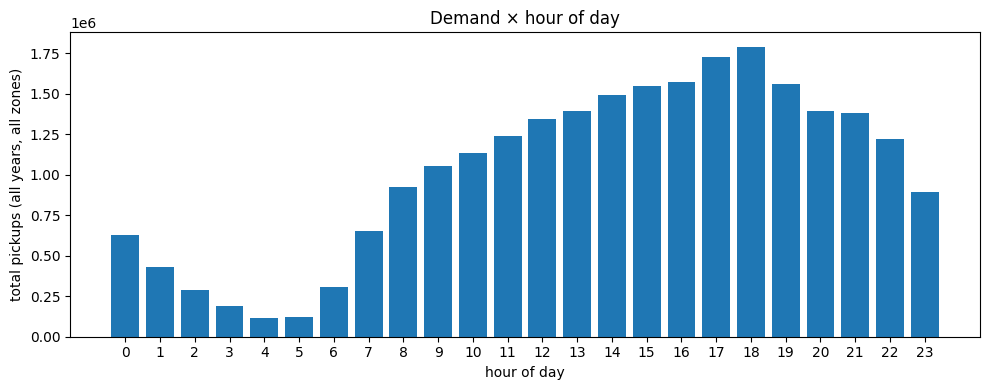

In [22]:
# Patrón demand × hour-of-day: ¿el pico está donde esperamos?
hourly = (
    demand.groupBy("hour_of_day")
    .agg(spark_sum("n_pickups").alias("total_pickups"))
    .orderBy("hour_of_day")
    .toPandas()
)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(hourly["hour_of_day"], hourly["total_pickups"])
ax.set_xlabel("hour of day")
ax.set_ylabel("total pickups (all years, all zones)")
ax.set_title("Demand × hour of day")
ax.set_xticks(range(0, 24))
plt.tight_layout()

## 12. Conclusiones

La capa gold publicada en `main` pasa todas las verificaciones definidas en este notebook sobre los 9 meses ingeridos (Q1 de 2023, 2024 y 2025):

- **Alcance de los datos (sección 1)**. Gold cubre los 9 meses del Q1 de 2023, 2024 y 2025. En esta ejecución ningún mes superó el umbral `MAX_DROP_RATIO = 0.3` del audit gate de silver, por lo que no hay tags `review/` en cuarentena y los 9 meses se propagan íntegros hasta gold.
- **Conservación de filas silver → gold (sección 6)**. `yellow_taxi_trips` tiene exactamente las mismas filas que `silver.yellow_taxi` en cada uno de los 9 meses (`diff = 0` en toda la tabla, 24.392.616 filas en total). El `LEFT JOIN` con la tabla de zonas no introduce duplicados ni pérdidas — los IDs PU/DO de silver están todos cubiertos por `silver.taxi_zone_lookup`.
- **Conservación de pickups en el agregado (sección 10)**. `sum(n_pickups)` de `pickup_demand_zone_hour` iguala al conteo de silver en los 9 meses (`diff = 0`). El group-by por `(pu_location_id, hour_bucket)` no descarta filas: 631.368 grupos contabilizan los 24.392.616 viajes.
- **Zonas NULL (secciones 5 y 11)**. Cero filas con `pu_borough` o `do_borough` NULL en `yellow_taxi_trips`, y cero `pu_borough` NULL en `pickup_demand_zone_hour`. El audit gate del ETL ya lo garantizaba; la tabla publicada lo confirma.
- **Coherencia de las columnas derivadas (sección 5)**. `pickup_year` y `pickup_month` coinciden con `year/month(pickup_datetime)` en todas las filas, y `trip_duration_minutes > 0` siempre. Esto último no es trivial: gold calcula la duración como `(unix_timestamp(dropoff) - unix_timestamp(pickup)) / 60`, que trunca a segundos; el hecho de que ninguna fila salga con duración 0 indica que en estos 9 meses no hay viajes sub-segundo que silver haya dejado pasar.
- **Particionado razonable (secciones 4 y 9)**. Iceberg ha creado 9 particiones mensuales en cada tabla — una por mes ingerido, sin fragmentación interna (1 fichero por partición). En `yellow_taxi_trips` los ficheros pesan ~51 MiB de media (457 MiB / 9), tamaño cómodo para escaneo por mes. El particionado `months(...)` y la naturaleza single-writer de los ETL explican esta distribución limpia.
- **Patrón horario plausible (sección 11)**. El histograma `Demand × hour of day` reproduce la forma esperada de NYC: valle nocturno (~04:00–05:00) y pico de tarde (~18:00–19:00). El top-10 de zonas con más pickups está dominado por Manhattan (Upper East Side South / North, Midtown Center / East, Times Square, Penn Station) más JFK Airport — coherente con los puntos de mayor densidad de demanda en el dataset.

La capa gold queda lista para consumo por las pipelines de ML (`src/ml/`), que leen exclusivamente de `nessie.nyc.*` en `main`.